# 03. Класичні моделі: M0, M1, M2

In [1]:
import itertools
import json
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sys.path.append(str(Path("..").resolve()))
from fabula_eval import LEVELS, annotator_level_ids, bootstrap_ci, class_f1, evaluate, macro_f1, plot_confusion
from fabula_features import FEATURE_GROUPS, FEATURE_NAMES
from fabula_models import RoundedRegressor, RuleBaseline

SEED = 42
PROCESSED_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")
RESULTS_DIR = Path("../results")
FIGURES_DIR = Path("../../docs/figures")
for directory in (MODELS_DIR, RESULTS_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)


def load_split(split):
    features = pd.read_csv(PROCESSED_DIR / f"features_{split}.csv")
    sentences = pd.read_csv(PROCESSED_DIR / f"cefr_sp_{split}.csv")
    assert (features["text"] == sentences["text"]).all()
    features["level_a"] = annotator_level_ids(sentences["label_a"])
    features["level_b"] = annotator_level_ids(sentences["label_b"])
    return features


train, validation, test = (load_split(split) for split in ["train", "validation", "test"])
X_train, y_train = train[FEATURE_NAMES], train["level_id"].to_numpy()
X_val, y_val = validation[FEATURE_NAMES], validation["level_id"].to_numpy()
X_test, y_test = test[FEATURE_NAMES], test["level_id"].to_numpy()


def score(split_frame, predictions):
    return evaluate(split_frame["level_id"], predictions, split_frame["level_a"], split_frame["level_b"])


print(X_train.shape, X_val.shape, X_test.shape)

(7002, 33) (1500, 33) (1501, 33)


## 1. Варіанти міток для навчання

In [2]:
def training_data(label_mode, feature_names=FEATURE_NAMES):
    if label_mode == "max":
        return train[feature_names], y_train
    features = pd.concat([train[feature_names], train[feature_names]], ignore_index=True)
    labels = np.concatenate([train["level_a"].to_numpy(), train["level_b"].to_numpy()])
    return features, labels


pd.DataFrame({
    mode: pd.Series(training_data(mode)[1]).value_counts().reindex(range(len(LEVELS))).set_axis(LEVELS)
    for mode in ["max", "both"]
}).rename(columns={"max": "max (вищий з двох)", "both": "both (обидві оцінки)"})

,max (вищий з двох),both (обидві оцінки)
A1,87,547
A2,890,2591
B1,2313,4914
B2,2331,4102
C,1381,1850


## 2. M0: rules

In [3]:
m0 = RuleBaseline().fit(X_train, y_train)
print("Пороги довжини (слів):", m0.length_thresholds_)
pd.DataFrame({"M0 rules": score(validation, m0.predict(X_val))}).T.round(3)

Пороги довжини (слів): [ 6.5  9.  13.  15.5]


,macro_f1,accuracy,adjacent_accuracy,qwk,f1_A1,f1_A2,f1_B1,f1_B2,f1_C,macro_f1_lenient,accuracy_lenient
M0 rules,0.405,0.451,0.91,0.59,0.19,0.501,0.458,0.468,0.407,0.632,0.613


## 3. Підбір M1 і M2 на validation

In [4]:
def grid(**options):
    keys = list(options)
    return [dict(zip(keys, values)) for values in itertools.product(*options.values())]


candidates = []
for params in grid(C=[0.01, 0.1, 1.0, 10.0], class_weight=[None, "balanced"]):
    candidates.append(("M1", "Logistic Regression", params, make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=3000, random_state=SEED, **params))))
for params in grid(alpha=[0.1, 1.0, 10.0]):
    candidates.append(("M1", "Ridge (ordinal)", params, RoundedRegressor(make_pipeline(
        StandardScaler(), Ridge(**params)))))
for params in grid(max_depth=[None, 12, 20], min_samples_leaf=[1, 5], class_weight=[None, "balanced_subsample"]):
    candidates.append(("M2", "Random Forest", params, RandomForestClassifier(
        n_estimators=400, n_jobs=-1, random_state=SEED, **params)))
for params in grid(learning_rate=[0.05, 0.1], max_leaf_nodes=[15, 31], class_weight=[None, "balanced"]):
    candidates.append(("M2", "Gradient Boosting", params, HistGradientBoostingClassifier(
        max_iter=400, early_stopping=True, validation_fraction=0.1, random_state=SEED, **params)))
for params in grid(learning_rate=[0.05, 0.1], max_leaf_nodes=[15, 31]):
    candidates.append(("M2", "Gradient Boosting Regressor (ordinal)", params, RoundedRegressor(
        HistGradientBoostingRegressor(max_iter=400, early_stopping=True, validation_fraction=0.1,
                                      random_state=SEED, **params))))

search_rows = []
fitted = {}
for label_mode in ["max", "both"]:
    features, labels = training_data(label_mode)
    for variant, family, params, template in candidates:
        started = time.perf_counter()
        model = clone(template).fit(features, labels)
        key = len(search_rows)
        fitted[key] = model
        search_rows.append({"key": key, "variant": variant, "family": family, "labels": label_mode,
                            "params": json.dumps(params), "fit_seconds": round(time.perf_counter() - started, 1),
                            **score(validation, model.predict(X_val))})

search = pd.DataFrame(search_rows)
search.to_csv(RESULTS_DIR / "03_validation_search.csv", index=False)
print(f"Навчено конфігурацій: {len(search)}")
search.sort_values("macro_f1", ascending=False).head(10).round(3)

Навчено конфігурацій: 70


,key,variant,family,labels,params,fit_seconds,macro_f1,accuracy,adjacent_accuracy,qwk,f1_A1,f1_A2,f1_B1,f1_B2,f1_C,macro_f1_lenient,accuracy_lenient
16,16,M2,Random Forest,max,"{""max_depth"": 12, ""min_samples_leaf"": 1, ""clas...",3.4,0.621,0.624,0.988,0.786,0.588,0.629,0.626,0.596,0.667,0.782,0.779
22,22,M2,Random Forest,max,"{""max_depth"": 20, ""min_samples_leaf"": 5, ""clas...",5.3,0.600,0.616,0.983,0.781,0.513,0.612,0.608,0.593,0.677,0.787,0.779
18,18,M2,Random Forest,max,"{""max_depth"": 12, ""min_samples_leaf"": 5, ""clas...",3.0,0.594,0.607,0.984,0.782,0.513,0.615,0.600,0.574,0.668,0.788,0.773
14,14,M2,Random Forest,max,"{""max_depth"": null, ""min_samples_leaf"": 5, ""cl...",2.4,0.588,0.609,0.985,0.780,0.474,0.607,0.602,0.583,0.672,0.780,0.775
6,6,M1,Logistic Regression,max,"{""C"": 10.0, ""class_weight"": null}",0.3,0.583,0.622,0.989,0.774,0.400,0.636,0.637,0.592,0.652,0.723,0.785
12,12,M2,Random Forest,max,"{""max_depth"": null, ""min_samples_leaf"": 1, ""cl...",1.8,0.578,0.628,0.989,0.771,0.385,0.581,0.643,0.616,0.663,0.717,0.775
20,20,M2,Random Forest,max,"{""max_depth"": 20, ""min_samples_leaf"": 1, ""clas...",4.0,0.572,0.623,0.989,0.767,0.385,0.576,0.643,0.611,0.648,0.713,0.771
30,30,M2,Gradient Boosting,max,"{""learning_rate"": 0.1, ""max_leaf_nodes"": 31, ""...",3.5,0.571,0.602,0.975,0.768,0.417,0.599,0.606,0.561,0.674,0.762,0.755
19,19,M2,Random Forest,max,"{""max_depth"": 20, ""min_samples_leaf"": 1, ""clas...",2.1,0.569,0.629,0.991,0.773,0.333,0.589,0.647,0.613,0.661,0.693,0.770
23,23,M2,Gradient Boosting,max,"{""learning_rate"": 0.05, ""max_leaf_nodes"": 15, ...",2.9,0.568,0.617,0.987,0.765,0.357,0.599,0.639,0.587,0.656,0.726,0.767


## 4. Найкращі конфігурації за родинами

In [5]:
best_by_family = search.loc[search.groupby("family")["macro_f1"].idxmax()].sort_values("macro_f1", ascending=False)
best_by_family[["variant", "family", "labels", "params", "macro_f1", "macro_f1_lenient",
                "adjacent_accuracy", "qwk", "f1_A1", "f1_C"]].round(3)

,variant,family,labels,params,macro_f1,macro_f1_lenient,adjacent_accuracy,qwk,f1_A1,f1_C
16,M2,Random Forest,max,"{""max_depth"": 12, ""min_samples_leaf"": 1, ""clas...",0.621,0.782,0.988,0.786,0.588,0.667
6,M1,Logistic Regression,max,"{""C"": 10.0, ""class_weight"": null}",0.583,0.723,0.989,0.774,0.400,0.652
30,M2,Gradient Boosting,max,"{""learning_rate"": 0.1, ""max_leaf_nodes"": 31, ""...",0.571,0.762,0.975,0.768,0.417,0.674
32,M2,Gradient Boosting Regressor (ordinal),max,"{""learning_rate"": 0.05, ""max_leaf_nodes"": 31}",0.557,0.685,0.991,0.766,0.273,0.602
10,M1,Ridge (ordinal),max,"{""alpha"": 10.0}",0.502,0.636,0.991,0.753,0.100,0.603


## 5. Мітки: max проти both

In [6]:
search.loc[search.groupby(["family", "labels"])["macro_f1"].idxmax()][
    ["family", "labels", "macro_f1", "macro_f1_lenient", "accuracy", "f1_A1", "f1_A2", "f1_C"]
].round(3)

,family,labels,macro_f1,macro_f1_lenient,accuracy,f1_A1,f1_A2,f1_C
62,Gradient Boosting,both,0.526,0.828,0.553,0.407,0.562,0.547
30,Gradient Boosting,max,0.571,0.762,0.602,0.417,0.599,0.674
66,Gradient Boosting Regressor (ordinal),both,0.505,0.814,0.555,0.348,0.568,0.455
32,Gradient Boosting Regressor (ordinal),max,0.557,0.685,0.628,0.273,0.635,0.602
41,Logistic Regression,both,0.504,0.820,0.542,0.364,0.557,0.499
6,Logistic Regression,max,0.583,0.723,0.622,0.400,0.636,0.652
50,Random Forest,both,0.538,0.829,0.560,0.478,0.573,0.496
16,Random Forest,max,0.621,0.782,0.624,0.588,0.629,0.667
45,Ridge (ordinal),both,0.466,0.730,0.555,0.148,0.595,0.444
10,Ridge (ordinal),max,0.502,0.636,0.610,0.100,0.553,0.603


## 6. Ваги класів: з вагами і без

In [7]:
weighted = search[search["family"].isin(["Logistic Regression", "Random Forest", "Gradient Boosting"])].copy()
weighted["class_weight"] = weighted["params"].map(lambda p: "так" if json.loads(p).get("class_weight") else "ні")
weighted.loc[weighted.groupby(["family", "labels", "class_weight"])["macro_f1"].idxmax()][
    ["family", "labels", "class_weight", "macro_f1", "accuracy", "f1_A1", "f1_A2", "f1_C"]
].round(3)

,family,labels,class_weight,macro_f1,accuracy,f1_A1,f1_A2,f1_C
62,Gradient Boosting,both,ні,0.526,0.553,0.407,0.562,0.547
65,Gradient Boosting,both,так,0.465,0.504,0.256,0.408,0.673
23,Gradient Boosting,max,ні,0.568,0.617,0.357,0.599,0.656
30,Gradient Boosting,max,так,0.571,0.602,0.417,0.599,0.674
41,Logistic Regression,both,ні,0.504,0.542,0.364,0.557,0.499
42,Logistic Regression,both,так,0.443,0.484,0.227,0.365,0.666
6,Logistic Regression,max,ні,0.583,0.622,0.400,0.636,0.652
7,Logistic Regression,max,так,0.493,0.544,0.261,0.475,0.657
50,Random Forest,both,ні,0.538,0.560,0.478,0.573,0.496
47,Random Forest,both,так,0.511,0.546,0.369,0.529,0.548


## 7. Відбір ознак: кореляція і взаємна інформація

In [8]:
spearman = pd.Series({name: spearmanr(X_train[name], y_train).statistic for name in FEATURE_NAMES})
discrete = [X_train[name].nunique() <= 10 for name in FEATURE_NAMES]
mutual_info = pd.Series(
    mutual_info_classif(X_train, y_train, discrete_features=discrete, random_state=SEED), index=FEATURE_NAMES
)
group_of = {name: group for group, names in FEATURE_GROUPS.items() for name in names}
relevance = pd.DataFrame({"група": pd.Series(group_of), "spearman": spearman, "mutual_info": mutual_info})
relevance.sort_values("mutual_info", ascending=False).round(3)

,група,spearman,mutual_info
min_zipf,lexical,-0.696,0.342
n_syllables,length,0.645,0.303
share_oov,lexical,0.590,0.274
share_a1,lexical,-0.554,0.268
syllables_per_word,length,0.493,0.227
chars_per_word,length,0.487,0.217
n_words,length,0.519,0.184
mean_word_level,lexical,0.470,0.182
max_word_level,lexical,0.501,0.169
mean_zipf,lexical,-0.495,0.148


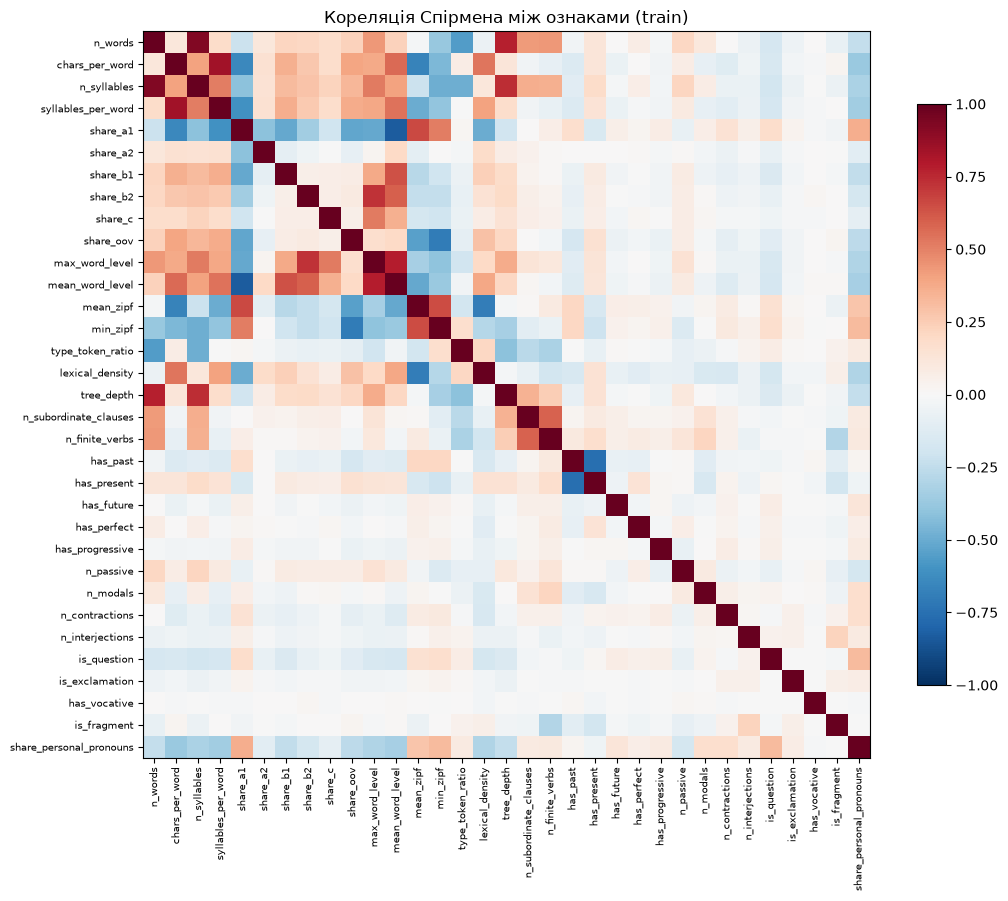

,,кореляція
n_words,n_syllables,0.923
chars_per_word,syllables_per_word,0.842
share_a1,mean_word_level,-0.830


In [9]:
correlation = X_train.corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURE_NAMES)), FEATURE_NAMES, rotation=90, fontsize=7)
ax.set_yticks(range(len(FEATURE_NAMES)), FEATURE_NAMES, fontsize=7)
fig.colorbar(image, ax=ax, shrink=0.8)
ax.set_title("Кореляція Спірмена між ознаками (train)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_feature_correlation.png", dpi=150)
plt.show()

pairs = correlation.where(np.triu(np.ones(correlation.shape, dtype=bool), k=1)).stack()
pairs[pairs.abs() >= 0.8].sort_values(key=np.abs, ascending=False).round(3).to_frame("кореляція")

## 8. Відбір ознак: важливість у найкращій моделі

In [10]:
best_row = search.loc[search[search["variant"] == "M2"]["macro_f1"].idxmax()]
best_model = fitted[int(best_row["key"])]
best_labels = best_row["labels"]
print("Найкраща M2:", best_row["family"], best_labels, best_row["params"], round(best_row["macro_f1"], 3))

importance = permutation_importance(
    best_model, X_val, y_val, scoring=lambda est, X, y: macro_f1(y, est.predict(X)),
    n_repeats=10, random_state=SEED, n_jobs=1,
)
relevance["permutation"] = importance.importances_mean
relevance.sort_values("permutation", ascending=False).round(4)

Найкраща M2: Random Forest max {"max_depth": 12, "min_samples_leaf": 1, "class_weight": "balanced_subsample"} 0.621


,група,spearman,mutual_info,permutation
n_syllables,length,0.6448,0.3028,0.1153
min_zipf,lexical,-0.6956,0.3423,0.1145
chars_per_word,length,0.4872,0.2174,0.0529
share_oov,lexical,0.5904,0.2742,0.0471
n_words,length,0.5194,0.1841,0.0452
share_a1,lexical,-0.5540,0.2685,0.0371
tree_depth,grammar,0.4505,0.1180,0.0318
max_word_level,lexical,0.5007,0.1690,0.0312
n_passive,grammar,0.1760,0.0206,0.0281
mean_word_level,lexical,0.4704,0.1817,0.0240


## 9. Абляція за групами ознак

In [11]:
def validation_score(feature_names):
    features, labels = training_data(best_labels, feature_names)
    model = clone(best_model).fit(features, labels)
    return macro_f1(y_val, model.predict(X_val[feature_names]))


ablation_rows = {"усі ознаки": {"ознак": len(FEATURE_NAMES), "macro_f1": validation_score(FEATURE_NAMES)}}
for group, names in FEATURE_GROUPS.items():
    without = [name for name in FEATURE_NAMES if name not in names]
    ablation_rows[f"без {group}"] = {"ознак": len(without), "macro_f1": validation_score(without)}
for group, names in FEATURE_GROUPS.items():
    ablation_rows[f"лише {group}"] = {"ознак": len(names), "macro_f1": validation_score(names)}
ablation = pd.DataFrame(ablation_rows).T
ablation["зміна"] = ablation["macro_f1"] - ablation.loc["усі ознаки", "macro_f1"]
ablation.to_csv(RESULTS_DIR / "03_ablation.csv")
ablation.round(3)

,ознак,macro_f1,зміна
усі ознаки,33.0,0.621,0.000
без length,29.0,0.554,-0.067
без lexical,21.0,0.491,-0.130
без grammar,23.0,0.600,-0.021
без dialogue,26.0,0.633,0.012
лише length,4.0,0.425,-0.197
лише lexical,12.0,0.531,-0.090
лише grammar,10.0,0.301,-0.320
лише dialogue,7.0,0.169,-0.452


## 10. Скільки ознак потрібно

Відібрано 13 ознак з 33: macro-F1 0.623 проти максимуму 0.623
['n_syllables', 'min_zipf', 'chars_per_word', 'share_oov', 'n_words', 'share_a1', 'tree_depth', 'max_word_level', 'n_passive', 'mean_word_level', 'lexical_density', 'type_token_ratio', 'share_b1']


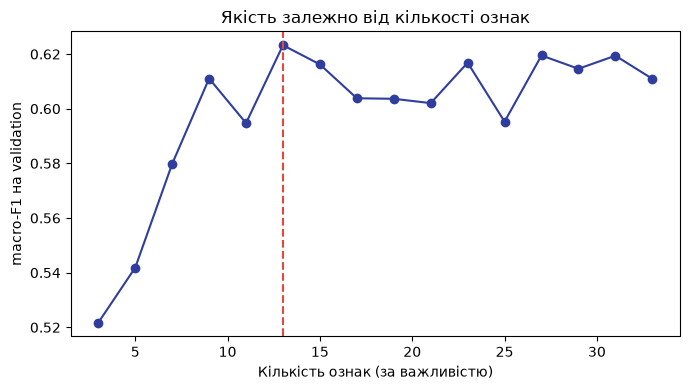

In [12]:
ranking = relevance["permutation"].sort_values(ascending=False).index.tolist()
sizes = sorted(set(range(3, len(ranking) + 1, 2)) | {len(ranking)})
curve = pd.Series({k: validation_score(ranking[:k]) for k in sizes})

tolerance = 0.005
selected_k = int(curve[curve >= curve.max() - tolerance].index.min())
selected_features = ranking[:selected_k]
print(f"Відібрано {selected_k} ознак з {len(ranking)}: macro-F1 {curve[selected_k]:.3f} проти максимуму {curve.max():.3f}")
print(selected_features)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(curve.index, curve.values, marker="o", color="#2F3E9E")
ax.axvline(selected_k, color="#E5483B", linestyle="--")
ax.set_xlabel("Кількість ознак (за важливістю)")
ax.set_ylabel("macro-F1 на validation")
ax.set_title("Якість залежно від кількості ознак")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_feature_count.png", dpi=150)
plt.show()

json.dump({"model": best_row["family"], "labels": best_labels, "params": json.loads(best_row["params"]),
           "features": selected_features},
          open(RESULTS_DIR / "03_selected_features.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

## 11. Оцінка на test

In [13]:
final_models = {"M0 rules": (m0, FEATURE_NAMES)}
for _, row in best_by_family.iterrows():
    final_models[f"{row['variant']} {row['family']} [{row['labels']}]"] = (fitted[int(row["key"])], FEATURE_NAMES)

selected_name = f"M2 {best_row['family']} [{best_labels}], {selected_k} ознак"
selected_model = clone(best_model).fit(*training_data(best_labels, selected_features))
final_models[selected_name] = (selected_model, selected_features)

test_rows, test_predictions = {}, {}
for name, (model, names) in final_models.items():
    predictions = model.predict(X_test[names])
    test_predictions[name] = predictions
    low, high = bootstrap_ci(y_test, predictions)
    a1_low, a1_high = bootstrap_ci(y_test, predictions, metric=class_f1(0))
    test_rows[name] = score(test, predictions) | {
        "macro_f1_ci": f"[{low:.3f}; {high:.3f}]", "f1_A1_ci": f"[{a1_low:.3f}; {a1_high:.3f}]"}

test_results = pd.DataFrame(test_rows).T
test_results.to_csv(RESULTS_DIR / "03_test.csv")
test_results[["macro_f1", "macro_f1_ci", "macro_f1_lenient", "accuracy", "accuracy_lenient",
              "adjacent_accuracy", "qwk", "f1_A1", "f1_A1_ci"]]

,macro_f1,macro_f1_ci,macro_f1_lenient,accuracy,accuracy_lenient,adjacent_accuracy,qwk,f1_A1,f1_A1_ci
M0 rules,0.395163,[0.360; 0.430],0.610691,0.440373,0.592938,0.912059,0.590831,0.184615,[0.064; 0.322]
M2 Random Forest [max],0.574506,[0.521; 0.624],0.738579,0.622252,0.78481,0.985343,0.778264,0.37037,[0.118; 0.581]
M1 Logistic Regression [max],0.532134,[0.484; 0.585],0.674535,0.61559,0.778148,0.98934,0.764421,0.181818,[0.000; 0.417]
M2 Gradient Boosting [max],0.539711,[0.496; 0.582],0.745704,0.587608,0.758827,0.977348,0.765825,0.318182,[0.143; 0.480]
M2 Gradient Boosting Regressor (ordinal) [max],0.563221,[0.506; 0.619],0.688935,0.635576,0.793471,0.988674,0.768032,0.285714,[0.000; 0.538]
M1 Ridge (ordinal) [max],0.473344,[0.448; 0.495],0.615119,0.600933,0.774817,0.991339,0.741841,0.0,[0.000; 0.000]
"M2 Random Forest [max], 13 ознак",0.580042,[0.521; 0.632],0.729114,0.621586,0.77948,0.983344,0.769771,0.4,[0.133; 0.621]


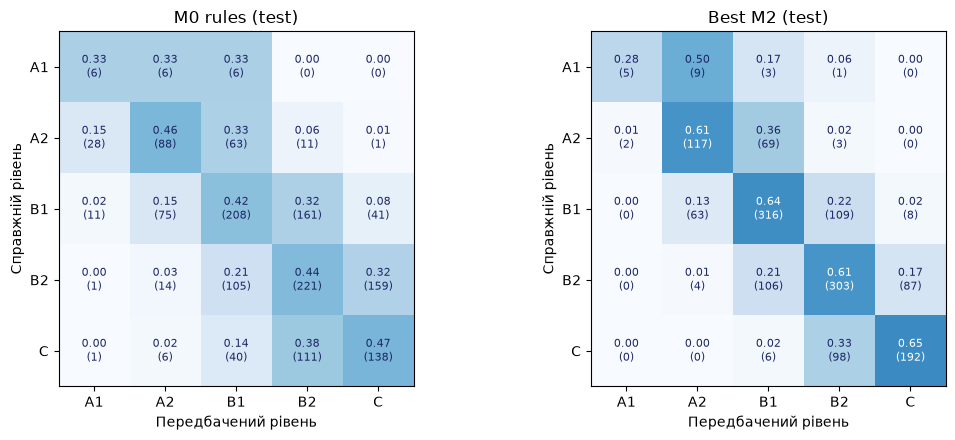

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_confusion(y_test, test_predictions["M0 rules"], "M0 rules (test)", ax=axes[0])
plot_confusion(y_test, test_predictions[selected_name], "Best M2 (test)", ax=axes[1])
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_confusion_test.png", dpi=150)
plt.show()

## 12. Ефект джерела

In [15]:
source_rows = {}
for source in sorted(test["source"].unique()):
    mask = (test["source"] == source).to_numpy()
    source_rows[source] = score(test[mask], test_predictions[selected_name][mask]) | {"речень": int(mask.sum())}
pd.DataFrame(source_rows).T.round(3)

,macro_f1,accuracy,adjacent_accuracy,qwk,f1_A1,f1_A2,f1_B1,f1_B2,f1_C,macro_f1_lenient,accuracy_lenient,речень
SCoRE,0.449,0.640,0.987,0.536,0.000,0.651,0.685,0.407,0.50,0.628,0.815,383.0
Wiki-Auto,0.635,0.615,0.982,0.694,0.833,0.472,0.601,0.608,0.66,0.765,0.767,1118.0


In [16]:
source_classifier = HistGradientBoostingClassifier(max_iter=300, random_state=SEED)
source_classifier.fit(X_train, train["source"])
source_accuracy = (source_classifier.predict(X_val) == validation["source"]).mean()
majority = validation["source"].value_counts(normalize=True).max()
print(f"Джерело за ознаками вгадується з точністю {source_accuracy:.3f} (частка більшого класу {majority:.3f})")

same_level = validation[validation["level"].isin(["A2", "B1"])]
same_level_accuracy = (source_classifier.predict(same_level[FEATURE_NAMES]) == same_level["source"]).mean()
print(f"Серед речень лише рівнів A2 і B1: {same_level_accuracy:.3f}")

Джерело за ознаками вгадується з точністю 0.927 (частка більшого класу 0.745)
Серед речень лише рівнів A2 і B1: 0.876


## 13. Збереження

In [17]:
joblib.dump({"model": selected_model, "features": selected_features, "levels": LEVELS, "labels": best_labels},
            MODELS_DIR / "m2_classic_best.joblib", compress=3)
joblib.dump({"model": m0, "features": FEATURE_NAMES, "levels": LEVELS}, MODELS_DIR / "m0_rules.joblib")
{path.name: f"{path.stat().st_size / 1e6:.1f} MB" for path in MODELS_DIR.glob("*.joblib")}

{'m0_rules.joblib': '0.0 MB', 'm2_classic_best.joblib': '22.4 MB'}

## 14. Висновки

| Модель (test) | macro-F1 | 95% ДІ | macro-F1 м'яка | ±1 рівень | QWK | F1 A1 |
| --- | --- | --- | --- | --- | --- | --- |
| M0 rules | 0.395 | 0.360–0.430 | 0.611 | 0.912 | 0.591 | 0.185 |
| M1 Logistic Regression | 0.532 | 0.484–0.585 | 0.675 | 0.989 | 0.764 | 0.182 |
| M2 Gradient Boosting | 0.540 | 0.496–0.582 | 0.746 | 0.977 | 0.766 | 0.318 |
| M2 Random Forest, 33 ознаки | 0.575 | 0.521–0.624 | 0.739 | 0.985 | 0.778 | 0.370 |
| **M2 Random Forest, 13 ознак** | **0.580** | 0.521–0.632 | 0.729 | 0.983 | 0.770 | 0.400 |

- М'яка метрика: передбачення правильне, якщо збігається з оцінкою будь-якого з двох анотаторів (як у статті CEFR-SP).
- Найкраща класична модель — Random Forest (max_depth 12, class_weight balanced_subsample), мітки max, 13 ознак.
- Навчання на обох оцінках (both): сувора macro-F1 нижча на 0.04–0.08, м'яка вища на 0.05–0.10; F1 A1 у Random Forest 0.588 → 0.478. Модель зміщується до середнього рівня анотаторів, а еталон — вищий рівень. Не використовується.
- Ваги класів: Random Forest +0.05 macro-F1, F1 A1 0.33 → 0.59 (validation); Logistic Regression гірше (0.583 → 0.493).
- Абляція: без lexical −0.130, без length −0.067, без grammar −0.021, без dialogue +0.012.
- 13 ознак дають ту саму якість, що 33; діалогові ознаки не відібрані.
- Сильно корельовані пари: n_words / n_syllables 0.92, chars_per_word / syllables_per_word 0.84, share_a1 / mean_word_level −0.83.
- Ефект джерела: macro-F1 SCoRE 0.449, Wiki-Auto 0.635; джерело вгадується з точністю 0.927 (0.876 серед A2 і B1).
- F1 A1 нестабільна: ДІ 0.13–0.62 (18 речень A1 у test).